# 014 风格迁移与特征反演：题目要求

**需要完成：** 实现并数值检查内容、Gram、风格和 TV 损失；完成三组指定风格迁移；执行随机初始化的特征反演；保存中间与最终图像。

**实验范围与验收：** 各组按原题固定参数执行 200 次像素优化，预训练骨干不重新训练。

**阅读顺序：** 先阅读原题和代码块前的中文解析，再检查实际输出与问题记录；若本题包含方法二，它紧随对应方法一，使用独立状态。方法一不得依赖方法二才能运行。

**课程参考：** [CS231n 课程资料](https://cs231n.github.io/)。本题的实现、检查和实验结果按下文顺序记录。

## 读代码前先看模型：内容与风格的像素优化

内容损失保留空间布局，风格损失比较通道相关性。网络作为固定测量工具，优化器只接收待生成图片的像素。

![内容与风格的像素优化的数据流](../assets/model_flow/014_StyleTransfer_PyTorch.svg)

**从定义推到实现。**

$$
G=FF^\top/(CHW),\quad L=\lambda_cL_c+\sum_l\lambda_l\|G_l-G_l^*\|_F^2+\lambda_{tv}L_{tv}
$$

F 的形状是 C×HW，所以 G 的每项是两个通道在所有位置上的内积。对称误差矩阵 E=G−G* 给出风格项对 F 的梯度 4EF/(CHW)，再沿冻结网络传回图片。TV 项累加相邻行列的差平方，抑制剧烈跳变。

**库在这里解决什么问题？** torchvision 提供冻结特征层，PyTorch 自动求导连接损失和像素，Adam 更新像素。内容图及风格图的目标特征只需计算一次。

**代入具体数值看公式。** 令两个通道的空间特征分别为 [1,2]、[3,4]，未归一化的 Gram 为 [[5,11],[11,25]]。同时交换两个空间位置，Gram 不变，所以它能描述风格相关性，却不能单独保证物体的位置。

## 从问题推到实现：Gram 的梯度怎样传回图像

**第 1 步。** 令 F∈R^(C×HW)，G=FFᵀ/Z，Z=CHW。每个 G_ab 是通道 a、b 在所有位置上的内积。空间列同时重排不会改变 G。

**第 2 步。** 风格项 L=wΣ(G−G*)²，记 E=G−G*。由 δG=(δF·Fᵀ+F·δFᵀ)/Z，代入 δL=2w〈E,δG〉。E 对称，两项相同，故 ∂L/∂F=4wEF/Z。

**第 3 步。** 这一梯度还需经特征网络的 Jacobian 回到像素。内容项对当前位置提供约束，TV 项对相邻像素差提供约束；优化器只持有待生成图像，固定网络参数不更新。

### 关键参数逐项读

- content_layer：读取哪一层的空间特征。
- content_weight：内容平方误差的权重。
- style_layers、style_weights：风格层号及一一对应的系数。
- tv_weight：空间平滑的权重。
- image_size、style_size：内容和风格图各自的短边尺寸。
- decay_lr_at=180：200 步优化中降低步长的位置。

### 库的整体职责与本题用法

| 库或项目包 | 整体职责 | 本题中的调用和目的 |
|---|---|---|
| `PIL` | Pillow 负责图像解码、像素读取、缩放和图像格式转换。 | 读取 RGB 图像，交给 transform 转成模型可接收的张量。 |
| `collections` | Python 标准库中常用的结构化容器和具名元组。 | 提供具名数据结构；是否实际创建由下面单元的调用决定。 |
| `cs231n` | 当前作业自己的本地 Python 包，封装教学数据、手写算子、模型与训练循环。 | 按当前题目加载本地模型、手写前后向和梯度检查工具。 |
| `matplotlib` | Matplotlib 是绘图库，负责把数值映射成坐标、曲线、像素和颜色。 | `plt.show` 将当前图提交给 notebook 显示；`plt.imshow` 按像素或色图显示数组，读取输出而不更新模型 |
| `numpy` | NumPy 是多维数组与数值计算库，提供广播、向量化、线性代数和随机采样。 | `np.random.seed` 设定 NumPy 的随机序列起点，便于重复同一初始化或梯度检查；`np.max` 沿指定轴得到最大数值，与 argmax 返回的位置索引区别开；`np.abs` 计算绝对值，使差异不因正负号相互抵消；`np.maximum` 逐位置取较大值，用于 ReLU 或 hinge 的截断 |
| `os` | Python 标准库的操作系统接口，管理路径、环境变量和文件操作。 | 提供运行环境接口；若当前单元只有 import，则仅注册模块。 |
| `pathlib` | Python 标准库的路径对象，用来表达目录关系和文件读写。 | 从当前作业目录定位项目根目录与结果文件。 |
| `random` | Python 标准库的伪随机数模块，与 NumPy 和 PyTorch 的随机状态分开。 | 固定 Python 的随机起点，或在图像优化中抽取平移量。 |
| `scipy` | SciPy 提供基于数值数组的科学计算算法，包括滤波等图像操作。 | 在本题执行图像的局部平滑或相关数值操作。 |
| `study_runtime` | 本项目的数据路径与实验记录辅助模块。 | `save_experiment` 保存已完成计算的模型与指标，避免把原始数据复制进检查点 |
| `sys` | Python 标准库的解释器接口，可配置模块搜索路径。 | 把项目根目录加入模块搜索路径，使本作业找到共享辅助代码。 |
| `threadpoolctl` | 控制底层数值库线程池的工具，可使计时实验的线程设置一致。 | `threadpool_limits` 限制底层数值线程，避免小矩阵计算受过多线程调度影响 |
| `torch` | PyTorch 提供 Tensor、设备管理、自动求导、神经网络模块和优化器。 | `torch.manual_seed` 设置 PyTorch 随机序列起点，与 NumPy 随机状态分开；`torch.sum` 将所选轴的多个贡献相加；`torch.pow(img[:, :, 1:] - img[:, :, :-1], 2).sum` 将所选轴的多个贡献相加；`torch.pow(img[:, :, :, 1:] - img[:, :, :, :-1], 2).sum` 将所选轴的多个贡献相加 |
| `torchvision` | torchvision 提供视觉数据集、图像预处理、模型结构及预训练权重。 | `T.ToTensor` 将图片变为通道优先的浮点张量；`T.Normalize` 逐通道减去给定均值，再除以相应标准差 |

## 读论文图：内容与风格分别保留哪些信息？

![艺术风格算法原论文图 1](https://ar5iv.labs.arxiv.org/html/1508.06576/assets/network_model.png)

Gatys、Ecker 与 Bethge，*A Neural Algorithm of Artistic Style*，2015 年预印本，图 1，PDF 第 3 页。[查看论文原页](https://arxiv.org/pdf/1508.06576#page=3)

内容重建匹配特定层的空间特征。较浅层保留更多像素细节，较深层仍能约束大的布局。风格重建匹配通道间的相关性，可以还原纹理，却不能仅靠这些统计锁定精确位置。

为什么 Gram 不记位置？将空间位置按同一个置换矩阵 P 重排，(FP)(FP)ᵀ=FPPᵀFᵀ=FFᵀ。因此两幅图可能有相似风格统计，却有完全不同的物体排列。内容损失补回空间约束，TV 项抑制邻近像素的剧烈跳变。

图中使用 VGG，而本题使用冻结的 SqueezeNet。目标内容特征和目标 Gram 只需计算一次；每轮重新计算的是当前生成图片的特征。梯度穿过特征网络回到像素，随后优化器更新图片。

# 样式传输
在这个笔记本中，我们将实现样式转换技术 ["Image Style Transfer Using Convolutional Neural Networks" (Gatys et al., CVPR 2015)](http://www.cv-foundation.org/openaccess/content_cvpr_2016/papers/Gatys_Image_Style_Transfer_CVPR_2016_paper.pdf).

总的思路是取两个图像，生成一个新的图像，反映其中一个的内容，但反映另一个的艺术“风格”。为此，我们将首先构造一个损失函数，该函数与深度网络特征空间中每个图像的内容和样式相匹配，然后对图像本身的像素进行梯度下降。

我们使用深度网络作为特征提取器[SqueezeNet](https://arxiv.org/abs/1602.07360),一个在ImageNet上训练过的小模型。你可以使用任何网络，但我们选择了SqueezeNet在这里，因为它的规模小，效率高。

这里有一个例子，你将能够产生的图像结束本笔记本:
![caption](example_styletransfer.png)

**本段解析**

**工作机制与执行链。** 这个单元初始化实验上下文。将当前作业的父目录加入 sys.path 后，Python 可以找到共享的 study_runtime；当前目录仍提供该 assignment 自己的 cs231n 包。NumPy 和标准库 random 分别设种子，threadpool_limits 设置 BLAS 的线程上限。下一单元才真正读取数据或实例化模型。

固定 NumPy 与 Python 随机种子为 231，读取共享数据配置，并限制 BLAS 线程数量。这样既能运行验证初始化和抽样，也能避免小矩阵运算中线程调度开销；原始数据文件保持不变。

**第 1 块：顺着变量读**

本块实际导入：`os`、`sys`、`random`、`pathlib.Path`、`study_runtime.data_path`、`numpy`、`threadpoolctl.threadpool_limits`。各模块在本题中的职责见开头的库说明。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `threadpool_limits` | `limits=4` | 底层 BLAS 线程数上限，影响并行调度和计时。 |
| `np.random.seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |

In [1]:
# 固定实验起点；读取共享数据路径；限制 BLAS 线程，避免多线程调度开销。
import os, sys, random
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from study_runtime import data_path
import numpy as np
from threadpoolctl import threadpool_limits
_blas_limit = threadpool_limits(limits=4)
np.random.seed(231)
random.seed(231)


## 环境准备

**第 2 块｜准备固定特征网络**

**工作机制与执行链。** 先固定用于度量特征差异的网络，再优化图片像素。输入图、目标特征和待优化图像承担不同角色。

导入模型、图像变换和损失所需依赖，固定 PyTorch 随机种子。风格迁移优化的是输出图像像素；预训练网络仅提供特征坐标系。

本块实际导入：`torch`、`torch.nn`、`torch.autograd.Variable`、`torchvision`、`torchvision.transforms`、`PIL`、`numpy`、`study_runtime.imread`、`collections.namedtuple`、`matplotlib.pyplot`、`cs231n.image_utils.SQUEEZENET_MEAN`、`cs231n.image_utils.SQUEEZENET_STD`。各模块在本题中的职责见开头的库说明。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `torch.manual_seed` | `seed=231` | 随机种子；数值梯度检查时用于重现相同掩码。 |

In [2]:
import torch
torch.manual_seed(231)
torch.set_num_threads(4)
import torch.nn as nn
from torch.autograd import Variable
import torchvision
import torchvision.transforms as T
import PIL

import numpy as np

from study_runtime import imread
from collections import namedtuple
import matplotlib.pyplot as plt

from cs231n.image_utils import SQUEEZENET_MEAN, SQUEEZENET_STD
%matplotlib inline

我们提供了一些帮助函数来处理图像，因为在这部分作业中，我们处理的是真正的jpeg，而不是CIFAR-10数据。

**第 3 块｜定义缩放和特征接口**

**工作机制与执行链。** 预处理保证短边尺寸和通道标准化正确，extract_features 的列表下标决定内容层与风格层。数值参考只有在相同预处理下才能比较。

建立图片预处理/反处理与逐层特征提取接口，并加载课程数值检查文件。图片按短边保持比例缩放，标准化使用 SqueezeNet 的 RGB 统计，不能把 HWC 图像直接传给卷积网络。

此处定义 `preprocess(img, size=512)`。函数体在调用时执行。

此处定义 `deprocess(img)`。函数体在调用时执行。

此处定义 `rescale(x)`。函数体在调用时执行。

- `T.Normalize(mean=SQUEEZENET_MEAN.tolist(), std=SQUEEZENET_STD.tolist())`：对每个通道减均值、除标准差，使输入尺度与模型约定一致。

本块产出的变量接着用于：`answers` → 第 7 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `preprocess` | `size=imgsize` | 采样时是输出尺寸；图像缩放时是目标尺寸。 |
| `extract_features` | `x=img_var` | 当前算子的输入；序列嵌入中可能是 token 整数索引。 |
| `T.Normalize` | `mean=SQUEEZENET_MEAN.tolist()` | 通道标准化时先减去的均值。 |
| `T.Normalize` | `std=SQUEEZENET_STD.tolist()` | 按通道除以的标准差向量，与初始化权重尺度无关。 |
| `T.Normalize` | `mean=[0, 0, 0]` | 通道标准化时先减去的均值。 |
| `T.Normalize` | `std=[1.0 / s for s in SQUEEZENET_STD.tolist()]` | 按通道除以的标准差向量，与初始化权重尺度无关。 |
| `T.Normalize` | `mean=[-m for m in SQUEEZENET_MEAN.tolist()]` | 通道标准化时先减去的均值。 |
| `T.Normalize` | `std=[1, 1, 1]` | 按通道除以的标准差向量，与初始化权重尺度无关。 |

In [3]:
def preprocess(img, size=512):
    transform = T.Compose([
        T.Resize(size),
        T.ToTensor(),
        T.Normalize(mean=SQUEEZENET_MEAN.tolist(),
                    std=SQUEEZENET_STD.tolist()),
        T.Lambda(lambda x: x[None]),
    ])
    return transform(img)

def deprocess(img):
    transform = T.Compose([
        T.Lambda(lambda x: x[0]),
        T.Normalize(mean=[0, 0, 0], std=[1.0 / s for s in SQUEEZENET_STD.tolist()]),
        T.Normalize(mean=[-m for m in SQUEEZENET_MEAN.tolist()], std=[1, 1, 1]),
        T.Lambda(rescale),
        T.ToPILImage(),
    ])
    return transform(img)

def rescale(x):
    low, high = x.min(), x.max()
    x_rescaled = (x - low) / (high - low)
    return x_rescaled

def rel_error(x,y):
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

def features_from_img(imgpath, imgsize):
    img = preprocess(PIL.Image.open(imgpath), size=imgsize)
    img_var = Variable(img.type(dtype))
    return extract_features(img_var, cnn), img_var

def check_scipy():
    import scipy
    vnum = int(scipy.__version__.split('.')[1])
    major_vnum = int(scipy.__version__.split('.')[0])
    assert vnum >= 16 or major_vnum >= 1, "You must install SciPy >= 0.16.0 to complete this notebook."

check_scipy()

answers = np.load('style-transfer-checks.npz')


和上一个任务一样，我们需要设置dtype来选择CPU或GPU

**第 4 块｜选择图像计算设备**

**工作机制与执行链。** 选择 CPU 或 CUDA float32 类型，后面 .type(dtype) 才实际完成转换。内容、目标和当前图片必须能在同一设备比较。

选择 CUDA float32（可用时）或 CPU float32 张量类型。模型、内容图、风格图和待优化图像必须在同一设备，尤其随机初始化图像也要转换设备。

本块产出的变量接着用于：`dtype` → 第 5 块。

In [4]:
dtype = torch.cuda.FloatTensor if torch.cuda.is_available() else torch.FloatTensor


**第 5 块｜逐层提取特征图**

**工作机制与执行链。** 冻结 SqueezeNet 的参数，并依次记录每一层输出。冻结权重不会阻断对输入像素的梯度，只是不为权重积累更新。

加载缓存的 SqueezeNet features 并冻结参数，定义 extract_features 按层保存特征图。列表下标直接对应课程指定的内容层和风格层，改变骨干或层序会改变损失含义。

此处定义 `extract_features(x, cnn)`。函数体在调用时执行。

前序输入：`dtype` 来自第 4 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `torchvision.models.squeezenet1_1` | `weights=torchvision.models.SqueezeNet1_1_Weights.IMAGENET1K_V1` | 选择指定版本的预训练网络参数。 |

In [5]:
cnn = torchvision.models.squeezenet1_1(weights=torchvision.models.SqueezeNet1_1_Weights.IMAGENET1K_V1).features
cnn.type(dtype)

for param in cnn.parameters():
    param.requires_grad = False

def extract_features(x, cnn):
    """输入一张预处理后的图像批次，顺序执行 cnn 的各层。返回列表中的第 l 项就是第 l 层的特征图，后续按层号取内容目标和风格目标。"""
    features = []
    prev_feat = x
    for i, module in enumerate(cnn._modules.values()):
        next_feat = module(prev_feat)
        features.append(next_feat)
        prev_feat = next_feat
    return features

## 计算损失
我们现在要计算损失函数的三个分量。损失函数是三个术语的加权和:内容损失+风格损失+总变化损失。你将填写下面计算这些加权项的函数。

## 内容损失
我们可以生成一个图像，反映一个图像的内容和另一个图像的风格，通过合并到我们的损失函数。我们想要处罚内容图像内容的偏离和样式图像样式的偏离。然后我们可以使用这个混合损失函数来执行梯度下降**不是对模型的参数**，而是对原始图像的像素值**。

让我们首先写内容损失函数。 内容丢失测量生成图像的特征映射与源图像的特征映射的差别有多大。我们只关心网络的一层( 说, 层) 的内容代表$\ell$),该图有特征地图$A^\ell \in \mathbb{R}^{1 \times C_\ell \times H_\ell \times W_\ell}$. $C_\ell$是图层中的过滤器/通道数$\ell$, $H_\ell$ and $W_\ell$高度和宽度。我们将使用这些特征图的重塑版,将所有空间位置合并为一个维度。$F^\ell \in \mathbb{R}^{N_\ell \times M_\ell}$成为当前图像的特征映射,并$P^\ell \in \mathbb{R}^{N_\ell \times M_\ell}$成为内容源图像的特征映射,其中$M_\ell=H_\ell\times W_\ell$表示每个特征图中的元素数。$F^\ell$ or $P^\ell$代表特定过滤器的矢量激活,在图像的所有位置上旋转。最后,请$w_c$成为损失函数中内容损失术语的权重。

然后内容损失由:

$L_c = w_c \times \sum_{i,j} (F_{ij}^{\ell} - P_{ij}^{\ell})^2$

**第 6 块｜定义内容特征误差**

**工作机制与执行链。** 内容损失是同一层、同一空间位置的特征平方差之和乘权重。当前图和目标图形状必须一致，结果保留空间布局信息。

内容损失比较同一层的当前图像特征与内容目标特征，平方差求和后乘内容权重。输入两张特征图形状相同，输出标量，用于约束空间结构接近内容图。

此处定义 `content_loss(content_weight, content_current, content_original)`。函数体在调用时执行。

In [6]:
def content_loss(content_weight, content_current, content_original):
    """输入当前与目标内容特征，形状相同。逐元素求差、平方、求和，再乘内容权重，返回可向像素求导的损失。"""
    return (content_current-content_original).pow(2).sum()*content_weight


测试您的内容损失。误差应该小于0.001。

**第 7 块｜核对内容损失**

**工作机制与执行链。** 用固定内容图、尺寸、层号和内容系数计算参考误差，验证的不只是公式，还包括缩放与预训练特征是否一致。

在指定内容图及层上调用内容损失测试，与课程参考值比较。检查结果受图像缩放、标准化和预训练权重影响，差异必须先定位这些输入条件。

此处定义 `content_loss_test(correct)`。函数体在调用时执行。

前序输入：`answers` 来自第 3 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `extract_features` | `x=bad_img` | 当前算子的输入；序列嵌入中可能是 token 整数索引。 |
| `rel_error` | `x=correct` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=student_output` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `content_loss` | `content_weight=content_weight` | 内容特征误差的权重。 |

**本段设置的变量与配置。**

- `content_image='styles/tubingen.jpg'`：提供内容特征目标的图片。
- `image_size=192`：内容图片缩放后的短边。
- `content_layer=3`：提供内容约束的特征层号。
- `content_weight=0.06`：内容特征平方误差的乘数。

In [7]:
def content_loss_test(correct):
    content_image = 'styles/tubingen.jpg'
    image_size =  192
    content_layer = 3
    content_weight = 6e-2
    
    c_feats, content_img_var = features_from_img(content_image, image_size)
    
    bad_img = torch.zeros(*content_img_var.data.size()).type(dtype)
    feats = extract_features(bad_img, cnn)
    
    student_output = content_loss(content_weight, c_feats[content_layer], feats[content_layer]).cpu().data.numpy()
    error = rel_error(correct, student_output)
    print('Maximum error is {:.3f}'.format(error))

content_loss_test(answers['cl_out'])

Maximum error is 0.000


## 样式丢失
现在我们可以处理风格的丢失。对于给定的层$\ell$，样式损失定义如下:
首先，计算代表每个滤波器响应之间相关性的Gram矩阵G，其中F如上所示。Gram矩阵是协方差矩阵的近似值——我们希望生成的图像的激活统计信息与样式图像的激活统计信息匹配，而匹配(近似)协方差是实现此目的的一种方法。有很多种方法可以做这个，但是克矩阵很好因为它很容易计算而且在实践中显示出很好的结果

带有特征映射$F^\ell$形状$(1, C_\ell, M_\ell)$, Gram矩阵有形状$(1, C_\ell, C_\ell)$其要素如下:

$$G_{ij}^\ell  = \sum_k F^{\ell}_{ik} F^{\ell}_{jk}$$

Assuming $G^\ell$是当前图像的特征图中的Gram矩阵,$A^\ell$是源样式图像的特征图中的Gram Matrix,以及$w_\ell$刻度权重术语,然后是图层的样式损失$\ell$仅仅是两个格姆矩阵之间的加权欧几里得距离:

$$L_s^\ell = w_\ell \sum_{i, j} \left(G^\ell_{ij} - A^\ell_{ij}\right)^2$$

在实际操作中,我们通常计算一组层的样式损失$\mathcal{L}$不只是一个单层$\ell$;然后总样式损失是每层样式损失的总和:

$$L_s = \sum_{\ell \in \mathcal{L}} L_s^\ell$$

开始采用如下格姆矩阵计算法:

**第 8 块｜计算通道 Gram 矩阵**

**工作机制与执行链。** 把 N×C×H×W 变为 N×C×HW，对每张图片独立计算 F·Fᵀ，并按设置除以 CHW。不要把 batch 合进通道轴。

将 (N,C,H,W) 特征展开为 (N,C,HW)，计算每个样本的 F·Fᵀ，得到 (N,C,C) Gram 矩阵。可选除以 C·H·W，使不同大小特征的量级更可比；Gram 描述通道相关性而不保留精确空间位置。

此处定义 `gram_matrix(features, normalize=True)`。函数体在调用时执行。

- `features.reshape(N, C, -1)`：按指定尺寸重排视图或数组，检查被合并的轴是否保留样本顺序。

In [8]:
def gram_matrix(features, normalize=True):
    """将特征从 (N,C,H,W) 展平为 (N,C,HW)。每张图的 F·Fᵀ 给出 C×C 通道相关矩阵，normalize 为真时除以 C·H·W。"""
    N,C,H,W=features.shape
    features=features.reshape(N,C,-1)
    gram=features.new_zeros((N,C,C))  # 创建 N 个 C×C 通道相关矩阵，沿用 features 的设备和精度。
    for i in range(N):
        # 把同一图片的各通道看作行，内积体现通道共同响应。不同图片分别计算，不跨 batch 合并。
        gram[i]+=features[i] @ (features[i].T)  # 每个通道是一行，将特征矩阵与自身转置相乘，结果是 C×C 的通道相关性矩阵。
    if normalize:
        gram/=H*W*C
    return gram

测试你的Gram矩阵代码。误差应该小于0.001。

**第 9 块｜核对 Gram 归一化**

**工作机制与执行链。** 在固定风格图上取指定特征层，比较所算 Gram 与参考数组。若误差偏大，应查轴顺序和归一化因子。

对固定风格图和网络层计算 Gram 矩阵，与参考数组比较。此检查不仅验证矩阵乘法，还验证展开轴和归一化因子的选择。

此处定义 `gram_matrix_test(correct)`。函数体在调用时执行。

前序输入：`answers` 来自第 3 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `rel_error` | `x=correct` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=student_output` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `gram_matrix` | `features=feats[5].clone()` | 每行对应一张图的视觉特征。 |

**本段设置的变量与配置。**

- `style_image='styles/starry_night.jpg'`：提供 Gram 目标的风格图片。
- `style_size=192`：风格图片缩放后的短边。

**这里没有显式传入、但实际生效的默认参数。**

- `gram_matrix(..., normalize=True)`：Gram 矩阵是否除以 C×H×W。

In [9]:
def gram_matrix_test(correct):
    style_image = 'styles/starry_night.jpg'
    style_size = 192
    feats, _ = features_from_img(style_image, style_size)
    student_output = gram_matrix(feats[5].clone()).cpu().data.numpy()
    error = rel_error(correct, student_output)
    print('Maximum error is {:.3f}'.format(error))
    
gram_matrix_test(answers['gm_out'])

Maximum error is 0.001


接下来，实现样式损失：

**第 10 块｜合并多个层的风格误差**

**工作机制与执行链。** 每个 style_layers[j] 对应一个目标 Gram 与一个权重。先算该层误差再乘对应系数，最后相加为统一标量。

在选定的多个风格层计算当前 Gram 与目标 Gram 的平方差，加权求和。每层都有独立权重，列表必须与 style_layers 对齐，输出的总风格损失仍可对图像求导。

此处定义 `style_loss(feats, style_layers, style_targets, style_weights)`。函数体在调用时执行。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `gram_matrix` | `features=feats[style_layers[i]]` | 每行对应一张图的视觉特征。 |

**这里没有显式传入、但实际生效的默认参数。**

- `gram_matrix(..., normalize=True)`：Gram 矩阵是否除以 C×H×W。

In [10]:
def style_loss(feats, style_layers, style_targets, style_weights):
    """在选定的各层分别计算当前 Gram 矩阵，与已缓存的风格目标作平方差，乘各层权重并求和。输入列表的层号、目标和权重必须一一对应。"""
    loss=feats[0].new_zeros((1))
    for i in range(len(style_weights)):
        t=gram_matrix(feats[style_layers[i]])
        loss+=style_weights[i]*torch.sum((t-style_targets[i])**2)
    return loss


测试您的样式损失实现。误差应小于0.001。

**第 11 块｜检查风格损失**

**工作机制与执行链。** 使用固定的内容、风格图片与层配置检查总风格损失。若总和不符，先逐层对照而非直接调整系数掩盖误差。

按固定图像、层和权重执行风格损失测试。若误差异常，先分别核验各层 Gram，再检查聚合，而不是直接调整总损失权重掩盖问题。

此处定义 `style_loss_test(correct)`。函数体在调用时执行。

前序输入：`answers` 来自第 3 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `rel_error` | `x=correct` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=student_output` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `gram_matrix` | `features=feats[idx].clone()` | 每行对应一张图的视觉特征。 |
| `style_loss` | `style_layers=style_layers` | 参与风格损失的层号。 |
| `style_loss` | `style_targets=style_targets` | 由风格图预先计算并缓存的 Gram 矩阵。 |
| `style_loss` | `style_weights=style_weights` | 每个风格层的误差权重，与层号逐项对齐。 |

**本段设置的变量与配置。**

- `content_image='styles/tubingen.jpg'`：提供内容特征目标的图片。
- `style_image='styles/starry_night.jpg'`：提供 Gram 目标的风格图片。
- `image_size=192`：内容图片缩放后的短边。
- `style_size=192`：风格图片缩放后的短边。
- `style_layers=[1, 4, 6, 7]`：参加风格损失的特征层号列表。
- `style_weights=[300000, 1000, 15, 3]`：与层号逐项对应的风格损失系数。

**这里没有显式传入、但实际生效的默认参数。**

- `gram_matrix(..., normalize=True)`：Gram 矩阵是否除以 C×H×W。

In [11]:
def style_loss_test(correct):
    content_image = 'styles/tubingen.jpg'
    style_image = 'styles/starry_night.jpg'
    image_size =  192
    style_size = 192
    style_layers = [1, 4, 6, 7]
    style_weights = [300000, 1000, 15, 3]
    
    c_feats, _ = features_from_img(content_image, image_size)
    feats, _ = features_from_img(style_image, style_size)
    style_targets = []
    for idx in style_layers:
        # 保存风格图在当前层的 Gram 目标。优化过程中更新的是生成图，不需每一步重新计算这个目标。
        style_targets.append(gram_matrix(feats[idx].clone()))  # 缓存风格图在该层的通道相关矩阵，后续像素优化重复使用同一目标。
    
    student_output = style_loss(c_feats, style_layers, style_targets, style_weights).cpu().data.numpy()
    error = rel_error(correct, student_output)
    print('Error is {:.3f}'.format(error))

    
style_loss_test(answers['sl_out'])

Error is 0.000


## 总变异正则化
事实证明，它也有助于促进图像的平滑。我们可以通过在损失中增加另一项来惩罚像素值的波动或“总变化”。

您可以计算“ 完全变异” ,作为所有对像素之间相邻的像素值的方形差异之和( 范围或垂直)。在这里,我们把3 个输入通道( RGB) 中每个输入通道的总变异重新加分, 并用总变异权重来加权总和损失,$w_t$:

$L_{tv} = w_t \times \sum_{c=1}^3\sum_{i=1}^{H-1} \sum_{j=1}^{W-1} \left( (x_{i,j+1, c} - x_{i,j,c})^2 + (x_{i+1, j,c} - x_{i,j,c})^2  \right)$

在下一个单元格中,填写电视损失术语的定义。要获得全额信用,您的执行不应有任何循环。

**第 12 块｜定义相邻像素平滑项**

**工作机制与执行链。** TV 在相邻行与相邻列分别求差平方，不在通道之间求差，也不把最后一列与第一列相连。

总变分损失分别计算水平方向和垂直方向相邻像素差的平方和，乘平滑权重。没有环绕边界差分；输出鼓励局部平滑，过强会抹去内容和风格细节。

此处定义 `tv_loss(img, tv_weight)`。函数体在调用时执行。

In [12]:
def tv_loss(img, tv_weight):
    """分别求相邻行和相邻列的像素差，累加平方后乘 tv_weight。输出是标量，增大其权重会更强地抑制局部跳变。"""
    return tv_weight*(torch.pow(img[:,:,1:]-img[:,:,:-1],2).sum()+torch.pow(img[:,:,:,1:]-img[:,:,:,:-1],2).sum())


测试你的TV损失实现。误差应小于0.001。

**第 13 块｜核对 TV 损失**

**工作机制与执行链。** 固定图像上核对 TV 标量，检查水平和垂直两个切片是否各少一个边界位置。权重只缩放这一项。

使用固定图像和总变分系数检查 TV 损失标量。形状切片必须对应相邻行、相邻列，不能误把通道差异计入空间平滑。

此处定义 `tv_loss_test(correct)`。函数体在调用时执行。

前序输入：`answers` 来自第 3 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `rel_error` | `x=correct` | 第一组待比较的数值，可为参考输出或数值梯度，不是训练输入。 |
| `rel_error` | `y=student_output` | 第二组待比较的数值，与 x 形状一致，不是类别标签。 |
| `preprocess` | `size=image_size` | 采样时是输出尺寸；图像缩放时是目标尺寸。 |
| `tv_loss` | `tv_weight=tv_weight` | 相邻像素平滑项的权重。 |

**本段设置的变量与配置。**

- `content_image='styles/tubingen.jpg'`：提供内容特征目标的图片。
- `image_size=192`：内容图片缩放后的短边。
- `tv_weight=0.02`：相邻像素平滑项的系数。

In [13]:
def tv_loss_test(correct):
    content_image = 'styles/tubingen.jpg'
    image_size =  192
    tv_weight = 2e-2

    content_img = preprocess(PIL.Image.open(content_image), size=image_size).type(dtype)
    
    student_output = tv_loss(content_img, tv_weight).cpu().data.numpy()
    error = rel_error(correct, student_output)
    print('Error is {:.3f}'.format(error))
    
tv_loss_test(answers['tv_out'])

Error is 0.000


现在我们准备好把它串在一起(你不应该修改这个函数):

**第 14 块｜用 Adam 更新图片像素**

**工作机制与执行链。** 先缓存目标，再重复计算当前图的内容、风格与 TV 项。Adam 只接收图片张量，200 次迭代中第 180 步切换到较低学习率。

先缓存内容目标与各风格层 Gram，再初始化输出图像；每步重新提取输出特征，计算内容、风格和 TV 总损失，对像素反向并用 Adam 更新。完整执行 200 步，在第 180 步降低学习率，过程中裁剪像素范围并显示结果。

此处定义 `style_transfer(content_image, style_image, image_size, style_size, content_layer, content_weight, style_layers, style_weights, tv_weight, init_random=False)`。函数体在调用时执行。

- `optimizer.zero_grad()`：清空上次更新遗留的梯度，为当前批次计算做准备。

- `loss.backward()`：沿已经构建的计算图反向传播损失，写入参数或输入的梯度。

- `optimizer.step()`：使用优化器保存的状态及当前梯度更新参数。

本块产出的变量接着用于：`style_transfer` → 第 15 块。

**本块调用中的参数。**

| 调用 | 形参与当前实参 | 作用 |
|---|---|---|
| `preprocess` | `size=image_size` | 采样时是输出尺寸；图像缩放时是目标尺寸。 |
| `extract_features` | `x=content_img_var` | 当前算子的输入；序列嵌入中可能是 token 整数索引。 |
| `preprocess` | `size=style_size` | 采样时是输出尺寸；图像缩放时是目标尺寸。 |
| `extract_features` | `x=style_img_var` | 当前算子的输入；序列嵌入中可能是 token 整数索引。 |
| `Variable` | `requires_grad=True` | 是否跟踪涉及该张量的运算以便反向求导。 |
| `torch.optim.Adam` | `lr=initial_lr` | 优化器的学习率。 |
| `extract_features` | `x=img_var` | 当前算子的输入；序列嵌入中可能是 token 整数索引。 |
| `content_loss` | `content_weight=content_weight` | 内容特征误差的权重。 |
| `style_loss` | `style_layers=style_layers` | 参与风格损失的层号。 |
| `style_loss` | `style_targets=style_targets` | 由风格图预先计算并缓存的 Gram 矩阵。 |
| `style_loss` | `style_weights=style_weights` | 每个风格层的误差权重，与层号逐项对齐。 |
| `tv_loss` | `tv_weight=tv_weight` | 相邻像素平滑项的权重。 |
| `gram_matrix` | `features=feats[idx].clone()` | 每行对应一张图的视觉特征。 |
| `torch.optim.Adam` | `lr=decayed_lr` | 优化器的学习率。 |

**本段设置的变量与配置。**

- `initial_lr=3.0`：像素优化初始步长。
- `decayed_lr=0.1`：衰减后的像素优化步长。
- `decay_lr_at=180`：切换步长的更新步骤。

**这里没有显式传入、但实际生效的默认参数。**

- `gram_matrix(..., normalize=True)`：Gram 矩阵是否除以 C×H×W。

In [14]:
def style_transfer(content_image, style_image, image_size, style_size, content_layer, content_weight,
                   style_layers, style_weights, tv_weight, init_random = False):
    """从内容图或随机图初始化待优化像素。先缓存内容和风格目标，再用 Adam 优化三项损失之和；固定特征网络，只对图片求梯度。"""
    
    content_img = preprocess(PIL.Image.open(content_image), size=image_size)
    content_img_var = Variable(content_img.type(dtype))
    feats = extract_features(content_img_var, cnn)
    content_target = feats[content_layer].clone()

    style_img = preprocess(PIL.Image.open(style_image), size=style_size)
    style_img_var = Variable(style_img.type(dtype))
    feats = extract_features(style_img_var, cnn)
    style_targets = []
    for idx in style_layers:
        # 保存风格图在当前层的 Gram 目标。优化过程中更新的是生成图，不需每一步重新计算这个目标。
        style_targets.append(gram_matrix(feats[idx].clone()))  # 缓存风格图在该层的通道相关矩阵，后续像素优化重复使用同一目标。

    if init_random:
        img = torch.empty_like(content_img).uniform_(0, 1).type(dtype)
    else:
        img = content_img.clone().type(dtype)

    img_var = Variable(img, requires_grad=True)

    initial_lr = 3.0
    decayed_lr = 0.1
    decay_lr_at = 180

    optimizer = torch.optim.Adam([img_var], lr=initial_lr)
    
    f, axarr = plt.subplots(1,2)
    axarr[0].axis('off')
    axarr[1].axis('off')
    axarr[0].set_title('Content Source Img.')
    axarr[1].set_title('Style Source Img.')
    axarr[0].imshow(deprocess(content_img.cpu()))
    axarr[1].imshow(deprocess(style_img.cpu()))
    plt.show()
    plt.figure()
    
    for t in range(200):
        if t < 190:
            img.clamp_(-1.5, 1.5)
        optimizer.zero_grad()  # 清除上一个批次累积的梯度，再为当前 batch 计算新的梯度。

        feats = extract_features(img_var, cnn)
        
        c_loss = content_loss(content_weight, feats[content_layer], content_target)
        s_loss = style_loss(feats, style_layers, style_targets, style_weights)
        t_loss = tv_loss(img_var, tv_weight) 
        loss = c_loss + s_loss + t_loss
        
        loss.backward()  # 从标量目标沿计算图计算梯度；参数更新发生在后面的优化器 step。

        if t == decay_lr_at:
            optimizer = torch.optim.Adam([img_var], lr=decayed_lr)
        optimizer.step()  # 根据当前参数梯度与优化器历史状态执行一次真实更新。

        if t % 100 == 0:
            print('Iteration {}'.format(t))
            plt.axis('off')
            plt.imshow(deprocess(img.cpu()))
            plt.show()
    print('Iteration {}'.format(t))
    plt.axis('off')
    plt.imshow(deprocess(img.cpu()))
    plt.show()

## 生成一些漂亮的图片!
在下面三个不同的参数集上尝试' style_transfer '。确保运行所有三个单元格。您可以随意添加自己的样式，但是请确保在您提交的笔记本中包含第三个参数集(星夜)的样式转换结果。
* ' content_image '是内容图像的文件名。
* ' style_image '是style image的文件名。
* “image_size”是内容图像的最小图像维数(用于内容丢失和生成图像)。
* ' style_size '是图像中最小的样式尺寸。
* ' content_layer '指定用于内容丢失的层。
* ' content_weight '给出了总体损失函数中内容损失的权重。增加这个参数的值将使最终的图像看起来更真实(更接近原始内容)。
* ' style_layers '指定一个用于样式丢失的层列表。
* ' style_weights '指定了一个用于style_layers中每一层的权重列表(每一个都会导致一个术语的整体风格丢失)。我们通常对早期的样式层使用更高的权重，因为它们描述了更多的局部/更小的尺度特征，这对纹理来说比在更大的接受域上的特征更重要。一般来说，增加这些权重会使生成的图像看起来不太像原始内容，而更倾向于样式图像的外观。
* ' tv_weight '指定总波动正则化在总损失函数中的权重。增加这个值会使生成的图像看起来更平滑，锯齿更少，代价是对样式和内容的保真度降低。

在接下来的三个代码单元格(不应该在其中更改超参数)下面，您可以随意复制和粘贴参数，看看结果图像是如何变化的。

**第 15 块｜运行《构成七号》风格**

**工作机制与执行链。** params1 按键名展开给 style_transfer。内容项保持图宾根的布局，多层风格 Gram 与参考画作比较，每个层号读取同位置的权重。

使用 Composition VII 与 Tubingen 的课程固定参数完成 200 步优化。风格图与内容图缩放尺寸不同，但 Gram 只比较通道相关性，因此允许空间尺寸不同。

前序输入：`style_transfer` 来自第 14 块。

**本段设置的变量与配置。**

- `content_image='styles/tubingen.jpg'`：提供内容特征目标的图片。
- `style_image='styles/composition_vii.jpg'`：提供 Gram 目标的风格图片。
- `image_size=192`：内容图片缩放后的短边。
- `style_size=512`：风格图片缩放后的短边。
- `content_layer=3`：提供内容约束的特征层号。
- `content_weight=0.05`：内容特征平方误差的乘数。
- `style_layers=(1, 4, 6, 7)`：参加风格损失的特征层号列表。
- `style_weights=(20000, 500, 12, 1)`：与层号逐项对应的风格损失系数。
- `tv_weight=0.05`：相邻像素平滑项的系数。

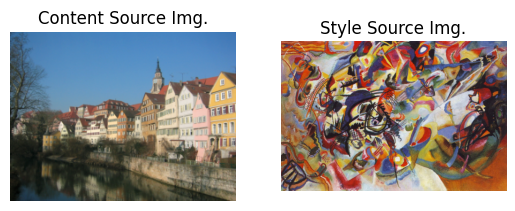

Iteration 0

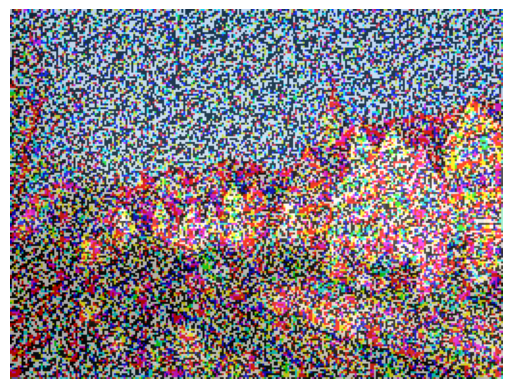

Iteration 100


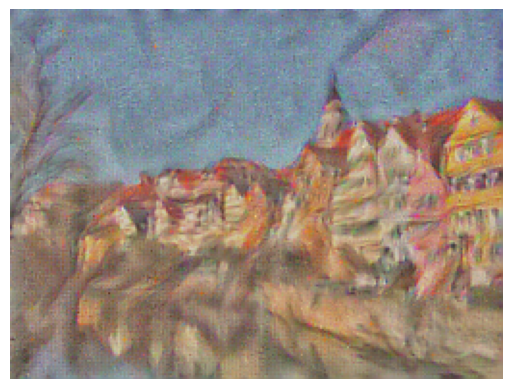

Iteration 199


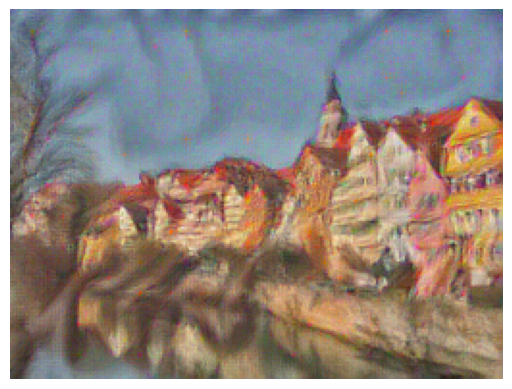

In [15]:
params1 = {
    'content_image' : 'styles/tubingen.jpg',
    'style_image' : 'styles/composition_vii.jpg',
    'image_size' : 192,
    'style_size' : 512,
    'content_layer' : 3,
    'content_weight' : 5e-2, 
    'style_layers' : (1, 4, 6, 7),
    'style_weights' : (20000, 500, 12, 1),
    'tv_weight' : 5e-2
}

style_transfer(**params1)

**第 16 块｜运行《呐喊》风格**

**工作机制与执行链。** 重新计算《呐喊》的目标 Gram 并执行完整像素优化。因为风格尺寸和权重也发生变化，不能把差别仅归于图片身份。

使用 The Scream 的固定参数完成第二组风格迁移，保持内容图不变。比较结果时关注风格权重、选层和 TV 权重的共同影响，不能把差别只归因于风格图片。

前序输入：`style_transfer` 来自第 14 块。

**本段设置的变量与配置。**

- `content_image='styles/tubingen.jpg'`：提供内容特征目标的图片。
- `style_image='styles/the_scream.jpg'`：提供 Gram 目标的风格图片。
- `image_size=192`：内容图片缩放后的短边。
- `style_size=224`：风格图片缩放后的短边。
- `content_layer=3`：提供内容约束的特征层号。
- `content_weight=0.03`：内容特征平方误差的乘数。
- `style_layers=[1, 4, 6, 7]`：参加风格损失的特征层号列表。
- `style_weights=[200000, 800, 12, 1]`：与层号逐项对应的风格损失系数。
- `tv_weight=0.02`：相邻像素平滑项的系数。

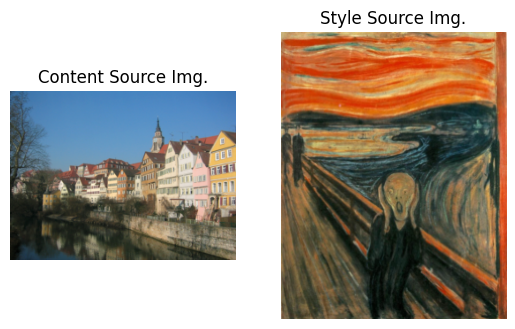

Iteration 0


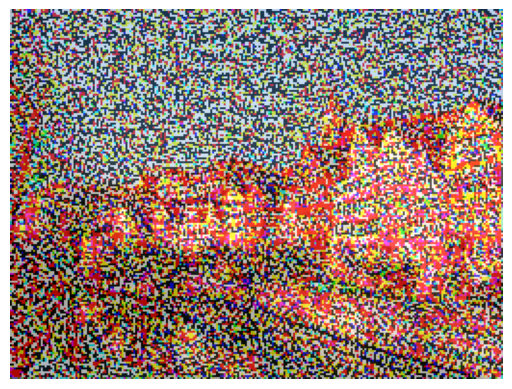

Iteration 100


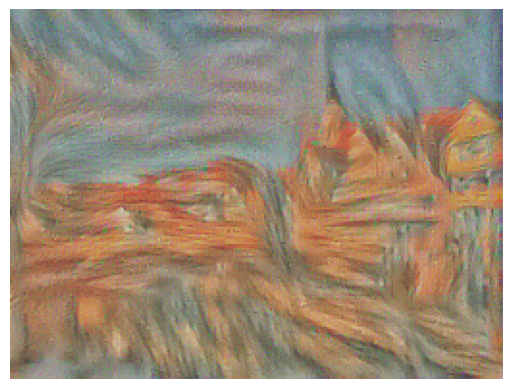

Iteration 199


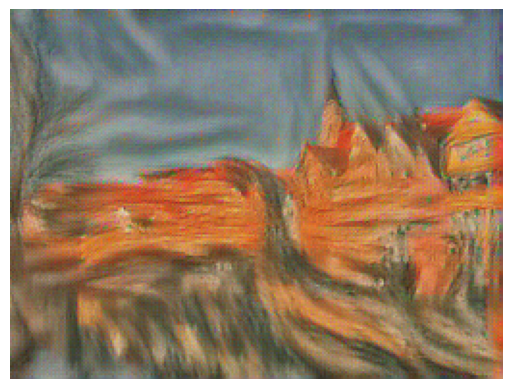

In [16]:
params2 = {
    'content_image':'styles/tubingen.jpg',
    'style_image':'styles/the_scream.jpg',
    'image_size':192,
    'style_size':224,
    'content_layer':3,
    'content_weight':3e-2,
    'style_layers':[1, 4, 6, 7],
    'style_weights':[200000, 800, 12, 1],
    'tv_weight':2e-2
}

style_transfer(**params2)

**第 17 块｜运行《星夜》风格**

**工作机制与执行链。** 用《星夜》运行第三组固定参数。目标 Gram 可缓存，而当前图的 Gram 每步必须重算，因为像素刚被优化器修改。

使用 Starry Night 的课程固定参数完成第三组实验。保存最终图及中间过程，满足原题要求；参数不为得到更漂亮的结果而静默改动。

前序输入：`style_transfer` 来自第 14 块。

**本段设置的变量与配置。**

- `content_image='styles/tubingen.jpg'`：提供内容特征目标的图片。
- `style_image='styles/starry_night.jpg'`：提供 Gram 目标的风格图片。
- `image_size=192`：内容图片缩放后的短边。
- `style_size=192`：风格图片缩放后的短边。
- `content_layer=3`：提供内容约束的特征层号。
- `content_weight=0.06`：内容特征平方误差的乘数。
- `style_layers=[1, 4, 6, 7]`：参加风格损失的特征层号列表。
- `style_weights=[300000, 1000, 15, 3]`：与层号逐项对应的风格损失系数。
- `tv_weight=0.02`：相邻像素平滑项的系数。

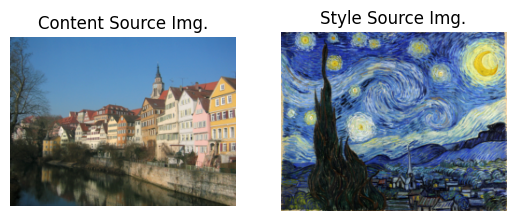

Iteration 0


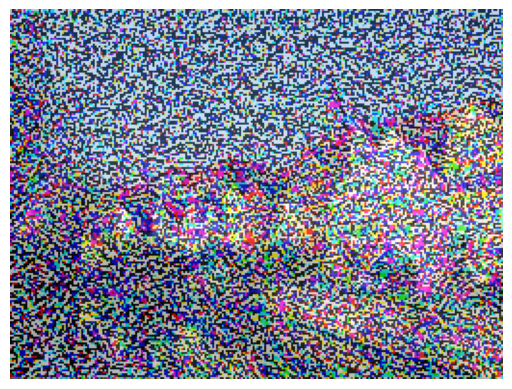

Iteration 100


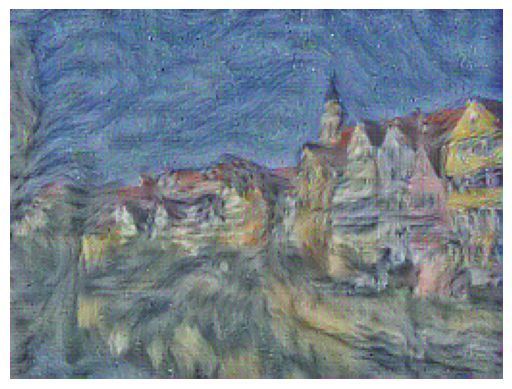

Iteration 199


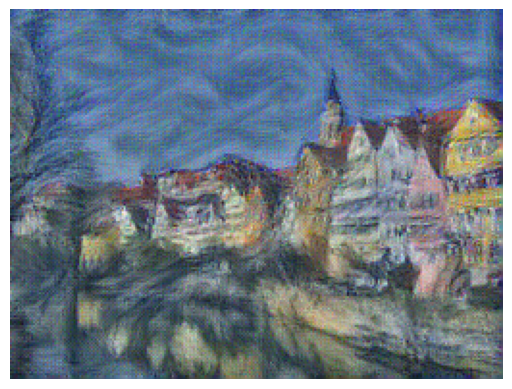

In [17]:
params3 = {
    'content_image' : 'styles/tubingen.jpg',
    'style_image' : 'styles/starry_night.jpg',
    'image_size' : 192,
    'style_size' : 192,
    'content_layer' : 3,
    'content_weight' : 6e-2,
    'style_layers' : [1, 4, 6, 7],
    'style_weights' : [300000, 1000, 15, 3],
    'tv_weight' : 2e-2
}

style_transfer(**params3)

## 特性反转
您编写的代码可以做另一件很酷的事情。为了理解卷积网络学会识别的特征类型，最近的一篇论文[1]试图从特征表示重建图像。我们可以很容易地使用来自预训练网络的图像梯度来实现这个想法，这正是我们在上面所做的(但是使用了两种不同的特性表示)。
现在，如果将样式权值设置为0，并将初始图像初始化为随机噪声图像，而不是内容源图像，那么您将从特征表示重构图像

[1] Aravindh Mahendran, Andrea Vedaldi,"通过倒置理解深层图像表现", CVPR 2015

**第 18 块｜从随机像素反演特征**

**工作机制与执行链。** 从随机像素初始化，风格层权重全为零，因此主要约束来自内容特征和 TV。此处研究特征反演，而不是把另一幅画的风格附加到图像。

按题目设置执行特征反演：从随机图像开始，以内容特征重建和相应正则约束进行优化。它说明中间特征保留了哪些结构，不能等同于逐像素恢复原图。

前序输入：`style_transfer` 来自第 14 块。

**本段设置的变量与配置。**

- `content_image='styles/tubingen.jpg'`：提供内容特征目标的图片。
- `style_image='styles/starry_night.jpg'`：提供 Gram 目标的风格图片。
- `image_size=192`：内容图片缩放后的短边。
- `style_size=192`：风格图片缩放后的短边。
- `content_layer=3`：提供内容约束的特征层号。
- `content_weight=0.06`：内容特征平方误差的乘数。
- `style_layers=[1, 4, 6, 7]`：参加风格损失的特征层号列表。
- `style_weights=[0, 0, 0, 0]`：与层号逐项对应的风格损失系数。
- `tv_weight=0.02`：相邻像素平滑项的系数。
- `init_random=True`：从噪声而非内容图片初始化。

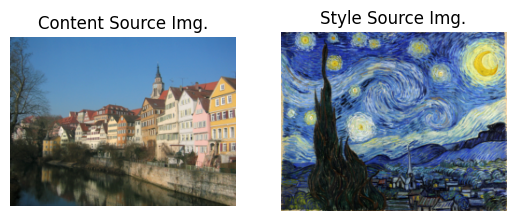

Iteration 0


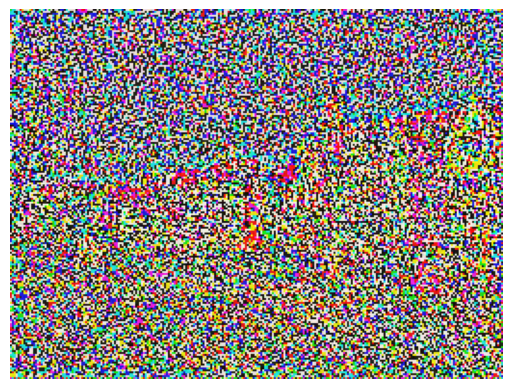

Iteration 100


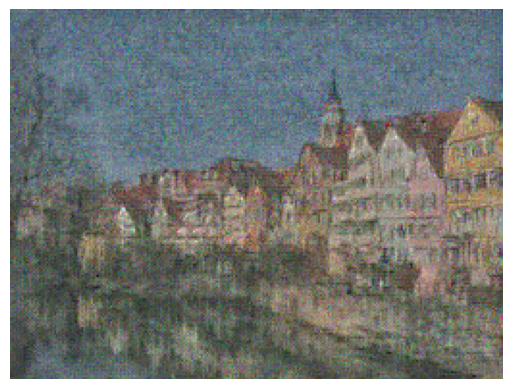

Iteration 199


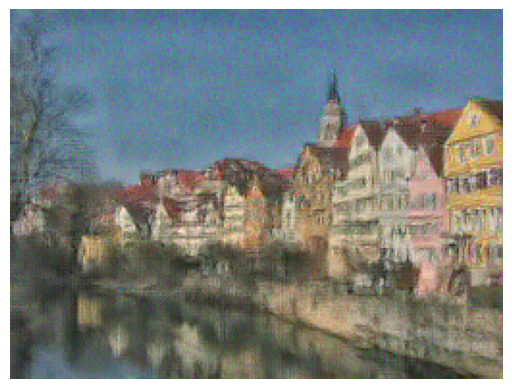

In [18]:
params_inv = {
    'content_image' : 'styles/tubingen.jpg',
    'style_image' : 'styles/starry_night.jpg',
    'image_size' : 192,
    'style_size' : 192,
    'content_layer' : 3,
    'content_weight' : 6e-2,
    'style_layers' : [1, 4, 6, 7],
    'style_weights' : [0, 0, 0, 0], 
    'tv_weight' : 2e-2,
    'init_random': True 
}

style_transfer(**params_inv)

### 保存本次实验
输入是上面实际训练得到的模型、指标和曲线。只保存模型参数与实验结果，不复制原始数据；输出写入本题独立目录，供运行验证核对。

**工作机制与执行链。** globals() 提供当前 notebook 的命名空间。save_experiment 按约定变量名读取已经算出的标量、曲线和模型，把它们写到本题独立输出目录。这里没有前向、反向或新的参数更新；没有适用标量的题，数值检查和图像仍保存在前面的单元输出。

**第 19 块：顺着变量读**

本块实际导入：`study_runtime.save_experiment`。各模块在本题中的职责见开头的库说明。

In [19]:
from study_runtime import save_experiment
experiment_metrics = save_experiment(globals(), '014_StyleTransfer_PyTorch')


本机实验指标： {}


## 实践补充：问题、检查与方法选择

**实际检查。** 四种损失通过双精度数值梯度检查。与旧版本固定图像参考的少量差异保留说明，没有篡改参考数组。

**优化边界。** 内容/风格目标特征固定，只有输出图像更新；忘记冻结骨干会改变问题本身。随机初始图像也必须放到同一设备。

**方法选择。** Gram 的批量矩阵乘法可简化代码，但本题每次优化一张图，未证明仅把单次循环改写就有实际训练收益，因此不为凑方法数量再重复一遍同目标优化。

更完整的故障证据见 [问题与解决记录](../003_问题与解决记录.md)。